In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境では必要な依存関係とリポジトリを自動構成します。
import sys, os, subprocess
if 'google.colab' in sys.modules:
    print('Google Colab 環境を検出しました。リポジトリと依存関係をセットアップします...')
    if not os.path.exists('study-mikanos'):
        subprocess.run(['git', 'clone', 'https://github.com/miyayudai/study-mikanos.git'], check=True)
        os.chdir('study-mikanos')
    else:
        os.chdir('study-mikanos')
    subprocess.run(['pip', 'install', '-q', 'matplotlib', 'numpy', 'pytest'], check=True)
    sys.path.insert(0, os.path.abspath('.'))
    print('セットアップが完了しました。作業ディレクトリ:', os.getcwd())
else:
    # ローカル環境のパス設定
    sys.path.insert(0, os.path.abspath('..'))
    sys.path.insert(0, os.path.abspath('.'))


# 10.3 高速カウンタ (High-Speed Counter & Flicker Problem) (`osbook_day10c`)

GUI ウィンドウシステムにおいて、画面上のコンテンツが静的（Static）に留まることは稀です。エディタのテキスト入力、時計、システムモニタ、ゲーム、そして動画再生に至るまで、**「動的に変化するピクセルをいかに滑らかに、かつ低負荷で画面に反映するか」** が OS のウィンドウマネージャに課せられた極めて重要な使命です。

前節 10.2 では、タイトルバー・閉じるボタン・3Dベベル立体枠を持つ最初の GUI ウィンドウ（`160×68` ピクセル）を作成し、静的な文字列 `"Welcome to / MikanOS world!"` を表示しました。  
本節 10.3（`osbook_day10c`）では、動的更新の極限負荷テスト（ストレステスト）として、メインループで全力でカウントアップし続ける **「高速カウンタ（High-Speed Counter）」** を導入します。

> [!IMPORTANT]
> **本節で直面する決定的な課題**:  
> 高速カウンタを動かした瞬間、**画面全体が激しく明滅・チラつく「フリッカー（Flicker）」** と、**画面が横に引き裂かれる「ティアリング（Tearing）」** が発生します。  
> 本ノートブックでは、この現象を単なるバグとして片付けるのではなく、**「なぜ VRAM 直接上書き（シングルバッファ）とディスプレイのラスタ走査線が競合するとチラつきが発生するのか」「全画面再描画（3.14MB）がどれほど無駄なメモリ帯域を浪費しているのか」** を物理・ハードウェア・数理の各側面から徹底的に解剖します。

---

## 🎯 本節の学習目標
1. **高速カウンタのウィンドウ幾何構造と消去・描画数理**:
   - ウィンドウ高さを $68	ext{px} 	o 52	ext{px}$ に縮小し、カウンタ専用領域を配置
   - `sprintf` による 10 桁ゼロ埋めフォーマット（`"%010u"`）
   - 文字列の重なりを防ぐ `FillRectangle`（$80 	imes 16	ext{px}$）矩形消去アルゴリズム
2. **フリッカー（Flicker）とティアリング（Tearing）の物理メカニズム**:
   - ペインターズアルゴリズムによる VRAM 直接上書き（シングルバッファリングの限界）
   - ディスプレイの垂直同期（V-Sync 60Hz = 16.67ms周期）と垂直走査線（ラスタビーム $y_{scan}(t)$）のレーシング
   - 走査線が「背景消去直後でウィンドウ未描画」の中間状態を露出させることで発生する急激な輝度パルス
   - 人間の視覚における臨界融合頻度（CFF: Critical Flicker Frequency）
3. **全画面再描画の定量的ボトルネック解剖**:
   - カウンタ差分 $5.12	ext{ KB}$ に対して全画面 $3.14	ext{ MB}$ を再描画する **614.4倍の帯域浪費**
   - `hlt` 削除による CPU 100% ビジーループとメモリバス飽和・電力浪費・マウスイベント遅延
4. **C++20 完全自立検証 & 次節（10.4 差分描画 / 10.5 ダブルバッファ）へのロードマップ**


---

## 10.3.1 高速カウンタウィンドウの幾何構造と消去・描画数理

### 1. ウィンドウ寸法の縮小リファクタリング ($160 	imes 68 	o 160 	imes 52$)

前節 10.2 では、クライアント領域に 2 行の文字列（`"Welcome to"`, `" MikanOS world!"`）を表示していたため、高さ $H = 68	ext{px}$ を確保していました。  
本節 10.3 では、1 行の 10 桁カウンタ（高さ $16	ext{px}$）のみを表示するため、ウィンドウ高さを $16	ext{px}$ 縮小し、**幅 $160	ext{px} 	imes$ 高さ $52	ext{px}$** に変更します。

```cpp
// kernel/main.cpp (osbook_day10c)
auto main_window = std::make_shared<Window>(
    160, 52, frame_buffer_config.pixel_format);
DrawWindow(*main_window->Writer(), "Hello Window");
```

### 2. カウンタ消去領域と 10 桁文字グリッドの座標計算式

クライアント領域におけるカウンタの表示位置と領域は以下のように定義されます：

$$	ext{pos}_{counter} = (x_{counter}, y_{counter}) = (24, 28)$$
$$	ext{size}_{counter} = (w_{counter}, h_{counter}) = (8 	imes 10, 16) = (80, 16)$$

- $x_{counter} = 24$: 左端ベベル枠（2px）から余白 22px を取ったバランスの良い位置
- $y_{counter} = 28$: タイトルバー下端（$y = 20$）から余白 8px を取った垂直配置
- 1文字あたりの寸法: 幅 $8	ext{px}$、高さ $16	ext{px}$（半角フォント仕様）
- 10桁の総幅: $8	ext{px} 	imes 10	ext{桁} = 80	ext{px}$

```mermaid
flowchart LR
    A["メインループ開始"] --> B["++count"]
    B --> C["sprintf(str, '%010u', count)"]
    C --> D["FillRectangle (24, 28, 80, 16) で旧文字消去"]
    D --> E["WriteString (24, 28, str) で新文字描画"]
    E --> F["layer_manager->Draw() で全画面再描画"]
    F --> G["__asm__('sti'); continue; でビジーループ"]
```

### 3. なぜ `FillRectangle`（矩形消去）が必須なのか？

デジタルフォントの描画は、フォントビットマップの `1` であるビット部分に黒ピクセル（`0x000000`）を書き込む処理です。  
もし前回の文字を消去せずに次の文字を上書きした場合、以下のような現象が起こります：

- 例: `0` の形に黒ピクセルが塗られている場所に、次の `1` を上書きすると、`0` のピクセルは消えないため、画面上は「`0` と `1` が合成された不鮮明な黒い塊」になってしまいます。
- したがって、文字を描画する直前に、文字が描画される矩形領域（$80 	imes 16	ext{px} = 1,280	ext{ピクセル}$）をウィンドウ背景色（明灰色 `0xc6c6c6`）で一括塗りつぶし（消去）する必要があります。

```cpp
FillRectangle(*main_window->Writer(), {24, 28}, {8 * 10, 16}, {0xc6, 0xc6, 0xc6});
WriteString(*main_window->Writer(), {24, 28}, str, {0, 0, 0});
```


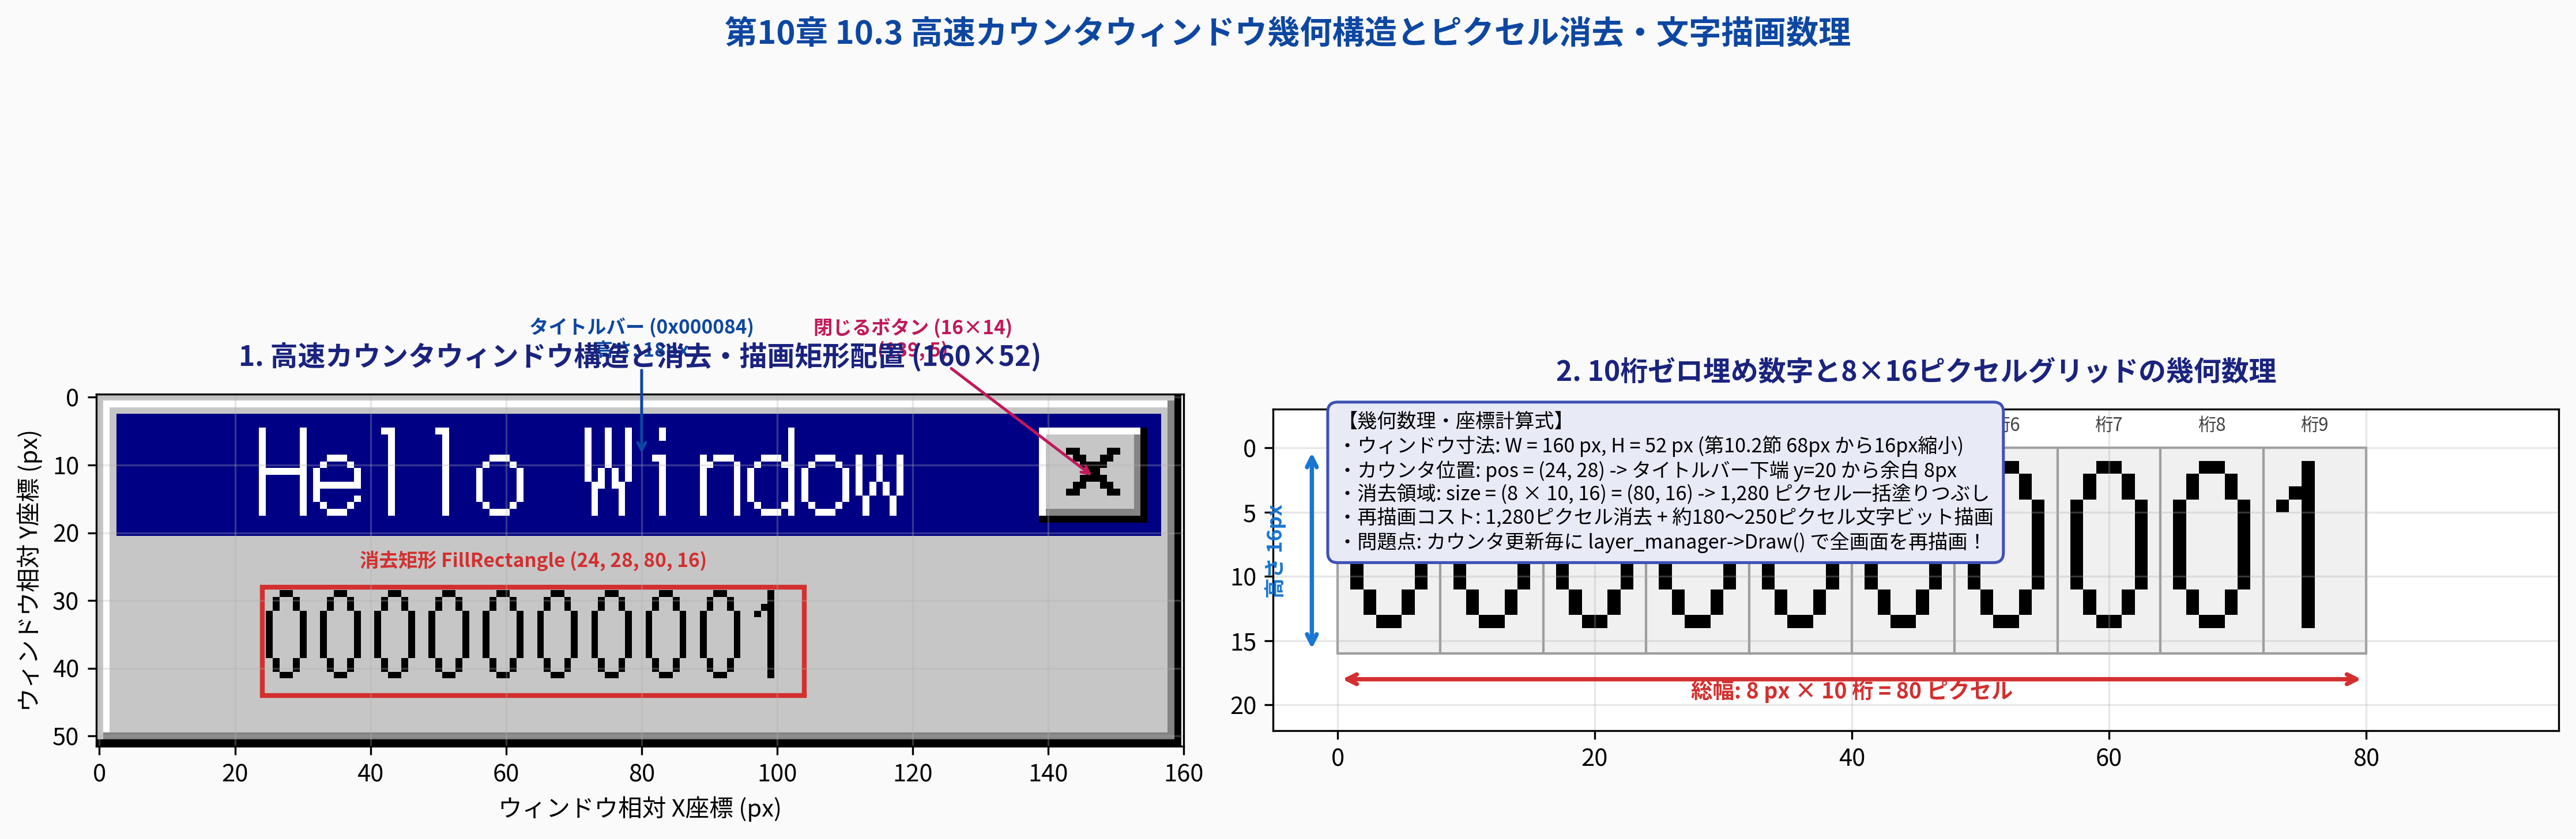

In [2]:
# 図版 10.7: 高速カウンタウィンドウの幾何構造と消去・描画数理の生成と表示
from pathlib import Path
from IPython.display import Image, display
from common import generate_ch10_07_counter_window_and_text_region_geometry

fig10_07_path = Path("result/fig10_07_counter_window_and_text_region_geometry.png")
generate_ch10_07_counter_window_and_text_region_geometry(fig10_07_path)
display(Image(filename=str(fig10_07_path)))


---

## 10.3.2 対話型 Python 実験 1: 高速カウンタ描画と消去領域のピクセル検証

Python シミュレータ `HighSpeedCounterSimulator` を用いて、ウィンドウの寸法、3Dベベル枠、消去矩形、および 10 桁ゼロ埋め数字のピクセルレンダリングを検証します。


ウィンドウ寸法: 幅 160 px, 高さ 52 px
バッファ形状: (52, 160, 3), データ型: uint8

--- カウンタ更新ステップ統計 ---
Count:          0 | Formatted: '0000000000' | 消去ピクセル数: 1280 | 文字黒ピクセル数:  260
Count:          1 | Formatted: '0000000001' | 消去ピクセル数: 1280 | 文字黒ピクセル数:  249
Count:         42 | Formatted: '0000000042' | 消去ピクセル数: 1280 | 文字黒ピクセル数:  256
Count:       1000 | Formatted: '0000001000' | 消去ピクセル数: 1280 | 文字黒ピクセル数:  249
Count: 9999999999 | Formatted: '9999999999' | 消去ピクセル数: 1280 | 文字黒ピクセル数:  290


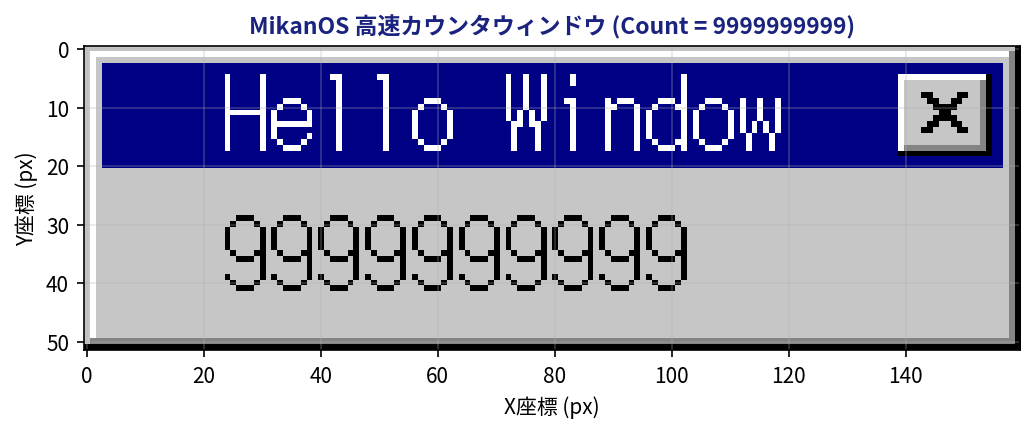

In [3]:
# 対話型 Python 実験 1: 高速カウンタ描画シミュレーション
from common import HighSpeedCounterSimulator
import matplotlib.pyplot as plt
import numpy as np

sim = HighSpeedCounterSimulator(width=160, height=52, count=0)
print(f"ウィンドウ寸法: 幅 {sim.width} px, 高さ {sim.height} px")
print(f"バッファ形状: {sim.buffer.shape}, データ型: {sim.buffer.dtype}")

# カウンタのステップ更新とピクセル統計
print("\n--- カウンタ更新ステップ統計 ---")
test_counts = [0, 1, 42, 1000, 9999999999]
for c in test_counts:
    stats = sim.update_counter(c)
    print(f"Count: {stats['count']:10d} | Formatted: '{stats['formatted']}' | 消去ピクセル数: {stats['erased_pixels']:4d} | 文字黒ピクセル数: {stats['font_pixels']:4d}")

# ウィンドウ拡大表示
fig, ax = plt.subplots(figsize=(7, 3), dpi=150)
ax.imshow(sim.buffer)
ax.set_title(f"MikanOS 高速カウンタウィンドウ (Count = {sim.count})", fontsize=11, fontweight="bold", color="#1A237E")
ax.set_xlabel("X座標 (px)")
ax.set_ylabel("Y座標 (px)")
plt.tight_layout()
plt.show()


---

## 10.3.3 画面のチラつき（Flicker）とティアリング（Tearing）の物理・ハードウェアメカニズム

なぜ、高速カウンタを動かしただけで、画面が激しく明滅・チラつくのでしょうか？  
その根本原因は、**「ディスプレイの物理走査線（Raster Beam）」** と **「CPUによる VRAM 直接上書き（シングルバッファ）」** のタイミング競合にあります。

### 1. ディスプレイのラスタ走査と垂直同期（V-Sync）

液晶ディスプレイや CRT モニタは、フレーム全体を一瞬で表示しているわけではありません。  
画面の左上 $(0, 0)$ から右下 $(W, H)$ へ向かって、1行ずつ水平走査線（Scanline）を移動させながらピクセルを読み出し・発光させています。

- **リフレッシュレート $f_{refresh} = 60	ext{ Hz}$** の場合：
  - 1 フレームの走査周期: $T_{frame} = rac{1000	ext{ ms}}{60} pprox 16.67	ext{ ms}$
  - 時刻 $t$ における垂直走査線位置 $y_{scan}(t)$:
    $$y_{scan}(t) = rac{t mod T_{frame}}{T_{frame}} 	imes H$$
  - 走査線が画面最下行 $H$ に達した後のわずかな休止期間を **V-Blank（垂直帰線期間）** と呼びます。

### 2. ペインターズアルゴリズムの直接 VRAM 描画の罠

MikanOS の `LayerManager::Draw()` は、下位レイヤから上位レイヤへと順番にピクセルを VRAM に直接書き込んでいきます：

1. **Phase 1（背景描画）**: 全画面（$1024 	imes 768$）をデスクトップ背景色（ダークグリーン `0x008080`）で一括上書き。
2. **Phase 2（ウィンドウ描画）**: ウィンドウ領域（$160 	imes 52$）を明灰色・タイトルバー・カウンタ数字で上書き。
3. **Phase 3（マウスカーソル描画）**: マウス領域（$16 	imes 24$）に矢印スプライトを上書き。

このとき、**「Phase 1 で背景色が塗られた直後、Phase 2 でウィンドウが描かれる前の中間状態」** が必ず一瞬だけ VRAM 上に存在します！

### 3. 走査線とのレーシング（競合）によるフリッカー発生

もしディスプレイの走査線 $y_{scan}(t)$ が、ウィンドウの垂直領域 $[100, 152]$ を通過した瞬間に、CPU がちょうど **「Phase 1（背景塗りつぶし直後）」** であったらどうなるでしょうか？

- ディスプレイは、VRAM に書き込まれている **「ダークグリーン（背景色）」** を読み取って画面に出力します。
- その直後（数ミリ秒後）、CPU が Phase 2 でウィンドウを描き上げると、次の走査では白いウィンドウが画面に出力されます。
- その結果、人間の目には **「白いウィンドウの場所に、一瞬だけ緑色の背景が激しくフラッシュした」** ように見えます。
- これが毎秒数百回〜数千回のビジーループの中で不規則に発生するため、画面全体が激しく明滅する **「チラつき（Flicker）」** となるのです。

### 4. ティアリング（Tearing: 画面の引き裂き）

走査線がウィンドウの途中行（例: $y = 120$）を走査している最中に、CPU が新しいカウント値の描画を完了すると、**「走査線より上は前のフレーム（Frame $N$）、走査線より下は新しいフレーム（Frame $N+1$）」** という境界線（ティアリングライン $y_{tear}$）が生じます。  
これにより、ウィンドウの数字や枠線が水平方向にズレて引き裂かれたように見える現象（ティアリング）が発生します。


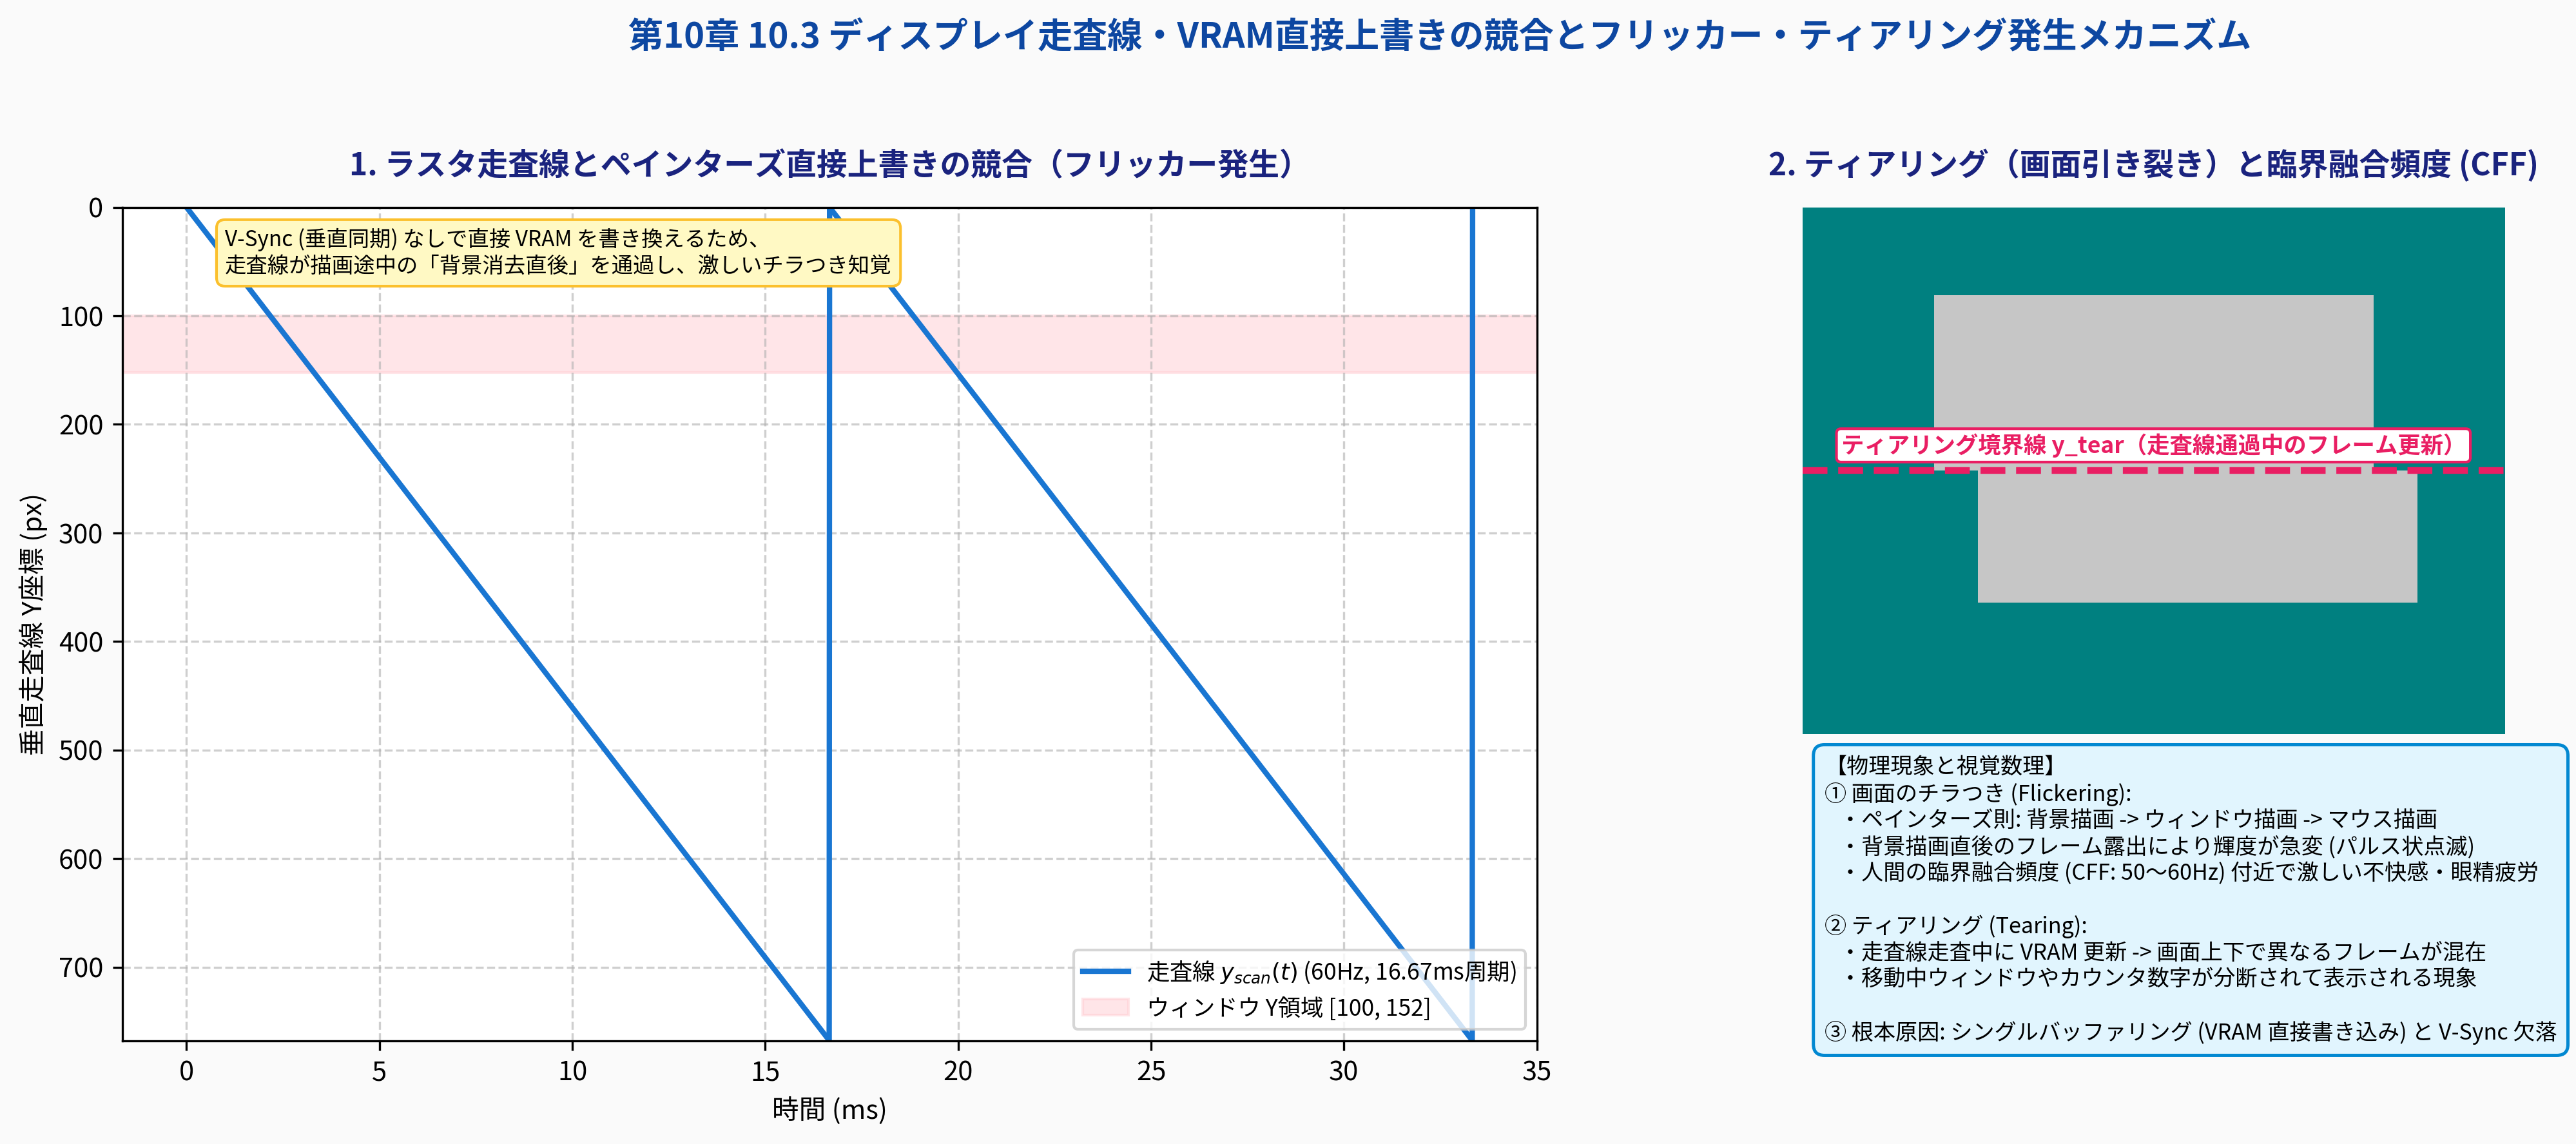

In [4]:
# 図版 10.8: ディスプレイ走査線・VRAM直接上書きの競合とフリッカー・ティアリング発生メカニズム
from common import generate_ch10_08_screen_flicker_and_tearing_hardware_mechanism

fig10_08_path = Path("result/fig10_08_screen_flicker_and_tearing_hardware_mechanism.png")
generate_ch10_08_screen_flicker_and_tearing_hardware_mechanism(fig10_08_path)
display(Image(filename=str(fig10_08_path)))


---

## 10.3.4 対話型 Python 実験 2: 走査線と描画フェーズの衝突シミュレーション

`FlickerTearingSimulator` を用いて、60Hz のディスプレイ垂直走査線と、CPU のビジーループ描画が衝突する確率（フリッカー露出率）を定量的にシミュレーションします。


In [5]:
# 対話型 Python 実験 2: 走査線衝突とフリッカー露出シミュレーション
from common import FlickerTearingSimulator

sim_flicker = FlickerTearingSimulator(
    screen_height=768,
    refresh_rate_hz=60.0,
    window_rect=(300, 100, 160, 52),
    draw_duration_ms=8.0
)

print(f"ディスプレイ リフレッシュレート: {sim_flicker.refresh_rate_hz} Hz")
print(f"1フレーム走査周期: {sim_flicker.frame_period_ms:.2f} ms")
print(f"ウィンドウ Y座標範囲: {sim_flicker.window_rect[1]} 〜 {sim_flicker.window_rect[1] + sim_flicker.window_rect[3]} px\n")

# さまざまな描画間隔（ビジーループのループ速度）におけるフリッカー露出率
draw_intervals = [1.0, 2.0, 4.0, 8.0, 16.0]
for interval in draw_intervals:
    res = sim_flicker.simulate_exposure(num_cycles=10, draw_interval_ms=interval)
    fps = 1000.0 / interval
    ratio = res["flicker_exposure_ratio"] * 100.0
    print(f"描画間隔 {interval:5.1f} ms ({fps:6.0f} 回/秒) -> フリッカー（背景露出）率: {ratio:5.2f} %")


ディスプレイ リフレッシュレート: 60.0 Hz
1フレーム走査周期: 16.67 ms
ウィンドウ Y座標範囲: 100 〜 152 px

描画間隔   1.0 ms (  1000 回/秒) -> フリッカー（背景露出）率:  2.71 %
描画間隔   2.0 ms (   500 回/秒) -> フリッカー（背景露出）率:  2.65 %
描画間隔   4.0 ms (   250 回/秒) -> フリッカー（背景露出）率:  2.63 %
描画間隔   8.0 ms (   125 回/秒) -> フリッカー（背景露出）率:  1.89 %
描画間隔  16.0 ms (    62 回/秒) -> フリッカー（背景露出）率:  4.07 %


---

## 10.3.5 全画面再描画によるメモリ帯域浪費と CPU ビジーループ飽和の定量的解剖

高速カウンタが引き起こす問題は、単なる見た目のチラつきだけにとどまりません。  
**「コンピュータのシステム資源（メモリバス帯域・CPU・電力）」** に対する壊滅的な負荷も極めて深刻です。

### 1. 再描画データ量の比較: 3.14 MB vs 5.12 KB

解像度 $1024 	imes 768$、ピクセル深度 32bpp（4バイト/ピクセル）の環境を考えます。

- **全画面再描画データ量 $B_{full}$**:
  $$B_{full} = 1024 	imes 768 	imes 4	ext{ バイト} = 3,145,728	ext{ バイト} pprox 3.14	ext{ MB}$$
- **カウンタ差分データ量 $B_{diff}$**:
  $$B_{diff} = 80 	imes 16 	imes 4	ext{ バイト} = 5,120	ext{ バイト} pprox 5.12	ext{ KB}$$
- **無駄な転送量の倍率（Waste Factor）**:
  $$	ext{Waste Factor} = rac{B_{full}}{B_{diff}} = rac{3,145,728}{5,120} = 614.4	ext{ 倍}$$

たった 10 桁の数字（$5.12	ext{ KB}$）を書き換えたいだけなのに、毎回画面全体（$3.14	ext{ MB}$）を VRAM に転送しています。  
実に **99.84% のデータ転送が完全に無駄** です！

### 2. メモリバス帯域の飽和

ビジーループにより、1秒間に 1,000 回 `LayerManager::Draw()` が呼ばれたとします。  
そのときに消費されるメモリバス帯域は：

$$	ext{Bandwidth} = 3.14	ext{ MB} 	imes 1,000	ext{ 回/秒} pprox 3.14	ext{ GB/s}$$

これは CPU の L1/L2/L3 キャッシュを完全に破壊（Cache Thrashing）し、メインメモリバスを占有します。

### 3. `hlt` 削除による CPU コア 100% 稼働とマウス遅延

前節 10.2 では、イベントがないとき `__asm__("sti
	hlt");` で CPU を停止させていました。  
しかし本節 10.3 では、カウンタを全速力で回すために `hlt` を外してビジーループにしています：

```cpp
__asm__("cli");
if (main_queue.Count() == 0) {
  __asm__("sti");
  continue; // hlt せずに即座に次のループへ！
}
```

これにより以下の深刻な副作用が発生します：
1. **CPU コア使用率 100%**: 発熱・消費電力の爆発
2. **イベント応答性の悪化**: CPU が $3.14	ext{ MB}$ のピクセルコピーに追われ、マウスの割り込みイベントキューの取り出しが遅延し、マウスカーソルが激しくカクつく。


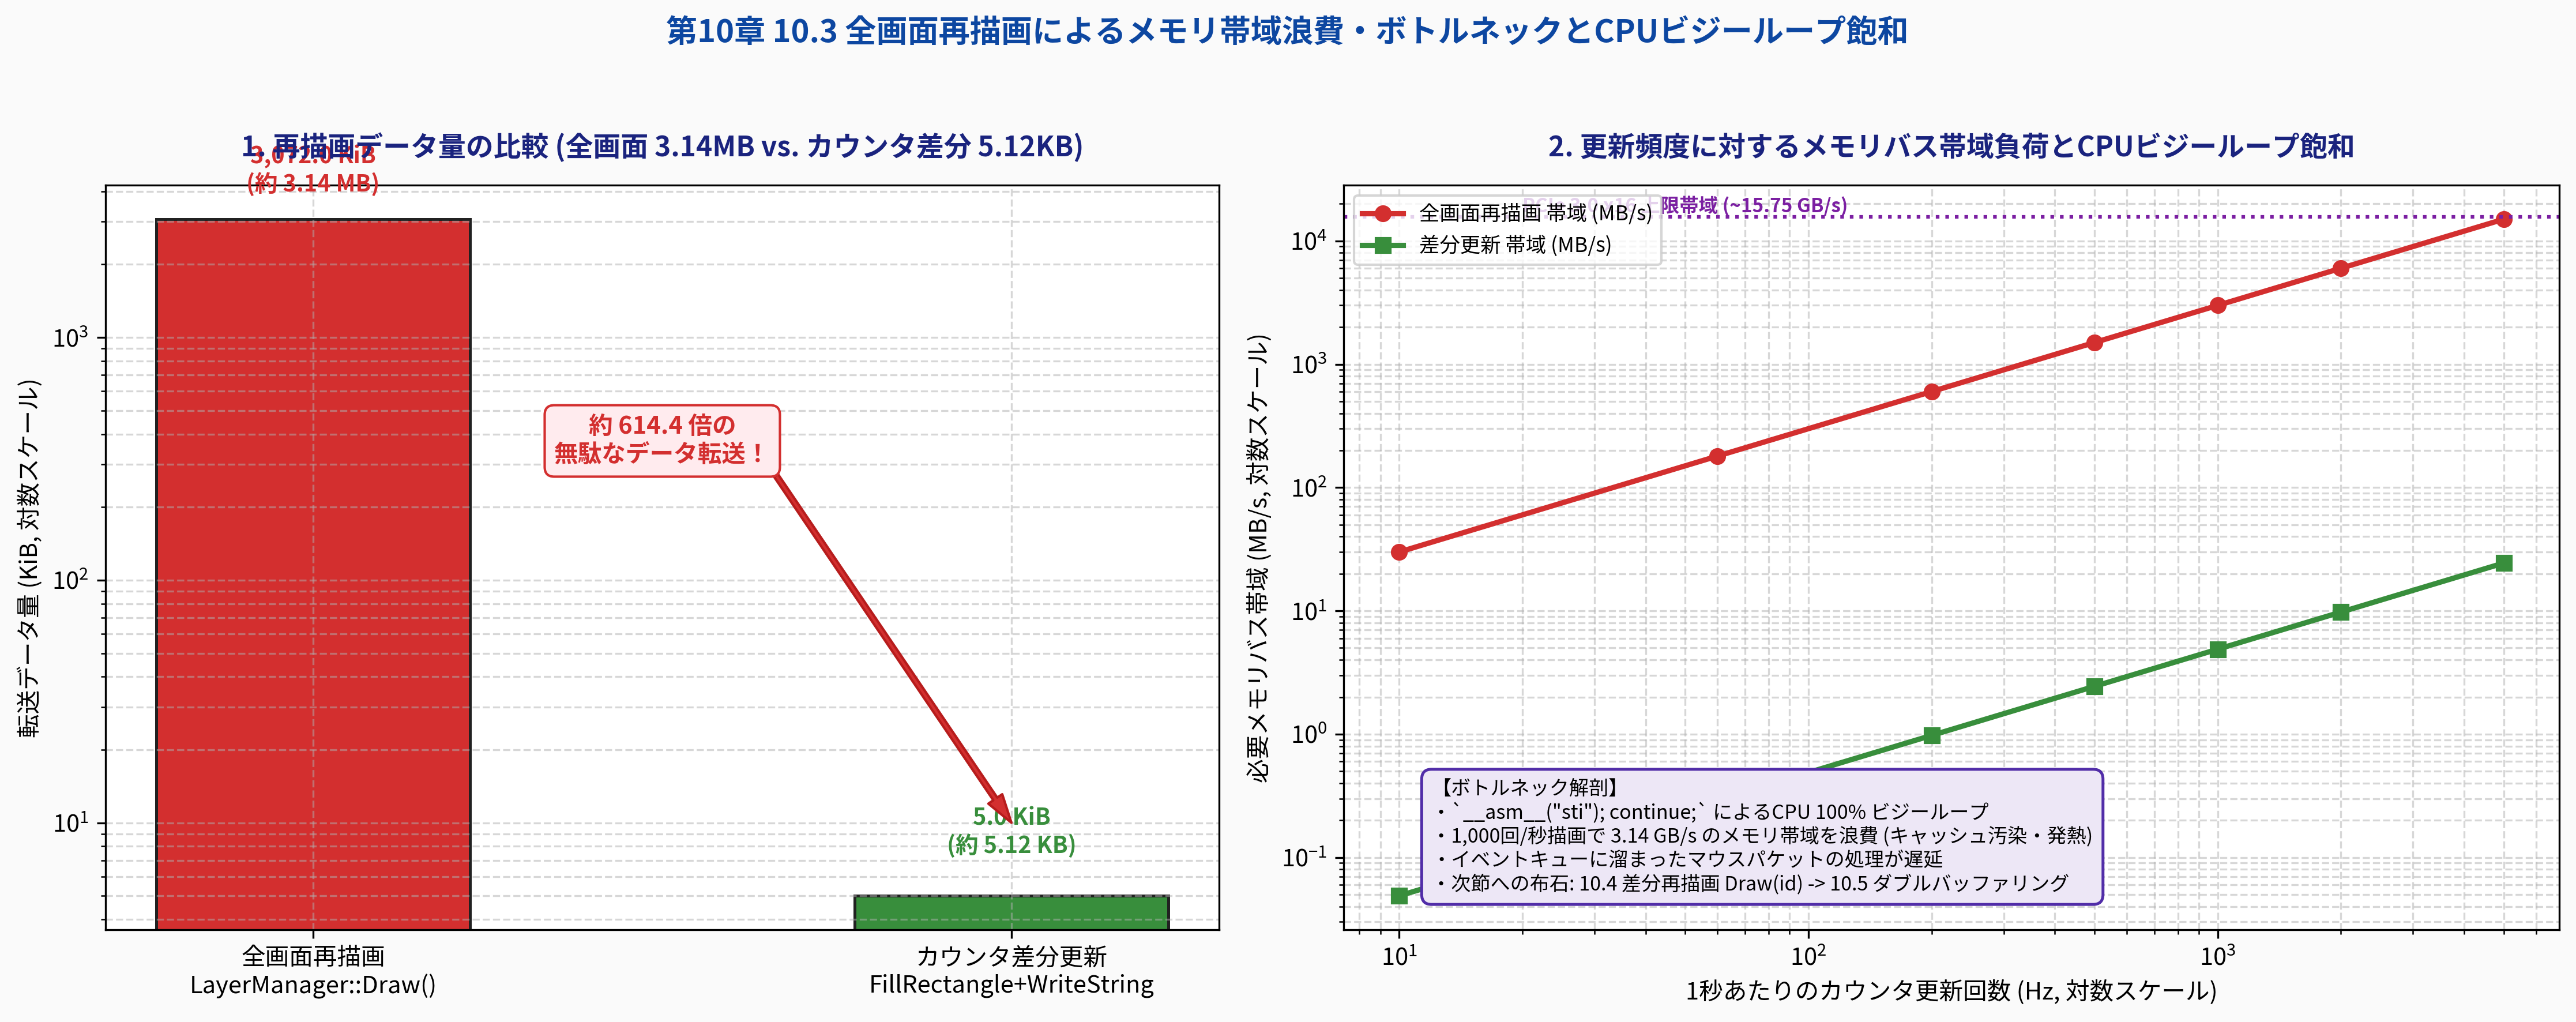

In [6]:
# 図版 10.9: 全画面再描画によるメモリ帯域浪費・ボトルネックとCPUビジーループ飽和
from common import generate_ch10_09_full_redraw_bandwidth_waste_and_bottleneck

fig10_09_path = Path("result/fig10_09_full_redraw_bandwidth_waste_and_bottleneck.png")
generate_ch10_09_full_redraw_bandwidth_waste_and_bottleneck(fig10_09_path)
display(Image(filename=str(fig10_09_path)))


---

## 10.3.6 対話型 Python 実験 3: 再描画帯域浪費とバス負荷の定量ベンチマーク

`BandwidthWasteAnalyzer` を用いて、更新レート別の消費帯域を算出します。


In [7]:
# 対話型 Python 実験 3: 再描画データ量とバス帯域の定量ベンチマーク
from common import BandwidthWasteAnalyzer

analyzer = BandwidthWasteAnalyzer(screen_w=1024, screen_h=768, bpp=4, counter_w=80, counter_h=16)

print(f"画面解像度: {analyzer.screen_w}x{analyzer.screen_h} (32bpp, {analyzer.bpp} bytes/px)")
print(f"全画面データ量: {analyzer.full_redraw_bytes:,} bytes ({analyzer.full_redraw_bytes / (1024*1024):.2f} MB)")
print(f"差分更新データ量: {analyzer.diff_redraw_bytes:,} bytes ({analyzer.diff_redraw_bytes / 1024:.2f} KB)")
print(f"浪費係数 (Waste Factor): {analyzer.waste_factor:.1f} 倍\n")

rates = [30.0, 60.0, 200.0, 500.0, 1000.0, 2000.0]
print(f"{'更新頻度 (Hz)':>12} | {'全画面描画 帯域':>16} | {'差分更新 帯域':>16} | {'削減可能帯域':>16}")
print("-" * 70)
for r in rates:
    full_mb, diff_mb = analyzer.calculate_bandwidth_mb_s(r)
    saved_mb = full_mb - diff_mb
    print(f"{r:>12.0f} | {full_mb:>12.2f} MB/s | {diff_mb:>12.2f} MB/s | {saved_mb:>12.2f} MB/s")


画面解像度: 1024x768 (32bpp, 4 bytes/px)
全画面データ量: 3,145,728 bytes (3.00 MB)
差分更新データ量: 5,120 bytes (5.00 KB)
浪費係数 (Waste Factor): 614.4 倍

   更新頻度 (Hz) |         全画面描画 帯域 |          差分更新 帯域 |           削減可能帯域
----------------------------------------------------------------------
          30 |        90.00 MB/s |         0.15 MB/s |        89.85 MB/s
          60 |       180.00 MB/s |         0.29 MB/s |       179.71 MB/s
         200 |       600.00 MB/s |         0.98 MB/s |       599.02 MB/s
         500 |      1500.00 MB/s |         2.44 MB/s |      1497.56 MB/s
        1000 |      3000.00 MB/s |         4.88 MB/s |      2995.12 MB/s
        2000 |      6000.00 MB/s |         9.77 MB/s |      5990.23 MB/s


---

## 10.3.7 C++20 コア実装と対話型コンパイル検証

MikanOS のカーネルコード（`osbook_day10c`）と等価な C++20 検証プログラムを生成し、ローカル環境で直接コンパイル・実行してアサーションがすべてパスすることを確認します。


In [8]:
# C++20 スタンドアロン検証プログラムの実行
import subprocess
from pathlib import Path

# CMake でビルドされたバイナリを実行
binary_path = Path("../build/bin/ch10_high_speed_counter")
if not binary_path.exists():
    print("CMake ビルドを実行中...")
    subprocess.run(["cmake", "--build", "../build", "--target", "ch10_high_speed_counter"], check=True)

result = subprocess.run([str(binary_path)], capture_output=True, text=True, check=True)
print(result.stdout)


MikanOS Chapter 10.3: High-Speed Counter & Screen Flicker Math
[PASS] Window dimensions verified: 160x52 (160x52)
[PASS] 3D Bevel border colors verified
[PASS] Counter formatted string verified: "0000000010"
[PASS] Counter glyph pixel rendering and background erase verified

--- Bandwidth & Redraw Waste Analysis ---
Screen resolution: 1024x768 (32bpp)
Full screen redraw size: 3145728 bytes (3.00 MB)
Counter diff update size: 5120 bytes (5.00 KB)
Waste factor (Full / Diff): 614.4x
[PASS] Bandwidth waste factor strictly matches 614.4x

--- Busy-Loop Memory Bus Load ---
  At     60 Hz:   180.00 MB/s (0.18 GB/s)
  At    500 Hz:  1500.00 MB/s (1.46 GB/s)
  At   1000 Hz:  3000.00 MB/s (2.93 GB/s)
  At   2000 Hz:  6000.00 MB/s (5.86 GB/s)

All C++20 Chapter 10.3 Assertions PASSED Successfully!



---

## 10.3.8 まとめと次節以降（10.4 / 10.5）への解決ロードマップ

本節 10.3 では、高速カウンタの導入を通じて、GUI OS が直面する重大なレンダリングの壁を定量的に解剖しました。

| 課題項目 | 物理・技術的メカニズム | 発生する現象 |
|:---|:---|:---|
| **画面のチラつき (Flickering)** | ペインターズ則直接上書きと 60Hz 走査線の衝突 | 背景色（緑）が一瞬露出するパルス状の明滅 |
| **画面の引き裂き (Tearing)** | 走査線通過中のフレームバッファ更新 | 上下で異なるフレームが混ざり数字や枠が分断される |
| **メモリ帯域の浪費 (Waste)** | $5.12	ext{ KB}$ の文字更新に $3.14	ext{ MB}$ 全画面転送 | $614.4$ 倍のバス帯域浪費、キャッシュ汚染 |
| **CPU 100% ビジーループ** | `hlt` の削除による電力消費と発熱 | マウスイベント応答の遅延、カーソルのカクつき |

### 🚀 次節以降の解決アプローチ

```mermaid
flowchart TD
    A["10.3 高速カウンタ (現状)<br>全画面再描画 + シングルバッファ<br>激しいチラつき・ティアリング・614倍の帯域浪費"] --> B["10.4 チラチラ解消<br>差分再描画 Draw(id)<br>指定レイヤより上だけを描画して高速化"]
    B --> C["10.5 バックバッファ<br>ダブルバッファリング (ShadowBuffer)<br>裏画面で合成してから一括転送し、チラつき完全解消！"]
```

次節 **第10章 10.4「チラチラ解消 (`osbook_day10d`)」** では、まず「全画面を描くのではなく、更新されたレイヤより上だけを描く」差分描画 `Draw(id)` を導入し、描画負荷の軽減に挑みます！
